# Trabajo 15 · 02 — Extracción de pose 2D (YOLOv8-Pose)

Este cuaderno continúa a `01_descarga_datasets-v2.ipynb`. Convierte **cada vídeo** de `data/metadata/` en una **serie temporal de esqueletos COCO-17** y la guarda en disco, de modo que el resto del proyecto (características, modelo, demo) ya no necesite volver a procesar vídeo.

**Qué hace**
1. Para cada clip detecta personas con `yolov8n-pose` y se queda con **la persona principal** (la que tiene mayor solape con la del fotograma anterior; en el primer fotograma, la de mayor área).
2. Guarda por clip un `.npz` con: `kpts_xy (T,17,2)`, `kpts_conf (T,17)`, `bbox (T,4)`, `detected (T,)`, `fps`.
3. Genera `data/processed/pose_index.csv` con métricas de calidad (% de fotogramas con persona, % con tobillos visibles...).
4. Comprueba visualmente la calidad (trayectorias de tobillos, tasa de detección por clase).
5. **Inspecciona las etiquetas de GAVD** (`gait_event`) para decidir cómo etiquetar los bloqueos (ver sección 5).

> Es idempotente: si el `.npz` de un clip ya existe, se omite (salvo `FORCE_REPROCESS = True`).

In [1]:
%pip install -q ultralytics torch opencv-python pandas numpy matplotlib tqdm

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 24.0 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


## 1. Configuración

In [2]:
from pathlib import Path
import numpy as np
import pandas as pd
import cv2
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import torch
from ultralytics import YOLO
    
# --- RUTAS (relativas a la carpeta del repositorio) ---
BASE_DIR = Path('data')
META_DIR = BASE_DIR / 'metadata'
POSE_DIR = BASE_DIR / 'processed' / 'pose'
POSE_INDEX_PATH = BASE_DIR / 'processed' / 'pose_index.csv'
POSE_DIR.mkdir(parents=True, exist_ok=True)

# --- PARÁMETROS ---
POSE_MODEL = 'yolov8n-pose.pt'   # 'yolov8s-pose.pt' si hay GPU y se quiere más precisión
CONF_PERSONA = 0.4               # confianza mínima de detección de persona
CONF_KPT = 0.4                   # confianza mínima para considerar visible un punto clave
MAX_FRAMES = None                # p.ej. 150 para pruebas rápidas; None = vídeo completo
FORCE_REPROCESS = False

# Índices COCO-17
KPT = dict(nariz=0, hombro_i=5, hombro_d=6, codo_i=7, codo_d=8, muneca_i=9, muneca_d=10,
           cadera_i=11, cadera_d=12, rodilla_i=13, rodilla_d=14, tobillo_i=15, tobillo_d=16)

d:\universidad\cuarto\primer_cuatri\entornos_inteligentes\trabajo_final\Trabajo-Final-Entornos-Inteligentes\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


## 2. Funciones de extracción

La selección de persona usa **IoU con el fotograma anterior** para no saltar entre personas cuando hay varias en escena (p. ej. el cuidador en GAVD). Los fotogramas sin persona se guardan como `NaN` y `detected=False`: **no se rellenan aquí**; la interpolación se decide en la etapa de características.

In [3]:
def iou_xyxy(a, b) -> float:
    x1, y1 = max(a[0], b[0]), max(a[1], b[1])
    x2, y2 = min(a[2], b[2]), min(a[3], b[3])
    inter = max(0.0, x2 - x1) * max(0.0, y2 - y1)
    area_a = max(0.0, a[2] - a[0]) * max(0.0, a[3] - a[1])
    area_b = max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])
    union = area_a + area_b - inter
    return inter / union if union > 0 else 0.0


def elegir_persona(boxes_xyxy: np.ndarray, prev_box):
    """Índice de la persona principal: mayor IoU con la anterior; si no hay anterior (o ninguna solapa), la de mayor área."""
    if prev_box is not None:
        ious = [iou_xyxy(b, prev_box) for b in boxes_xyxy]
        if max(ious) > 0.1:
            return int(np.argmax(ious))
    areas = (boxes_xyxy[:, 2] - boxes_xyxy[:, 0]) * (boxes_xyxy[:, 3] - boxes_xyxy[:, 1])
    return int(np.argmax(areas))


def extraer_pose_video(ruta_video: Path, detector, max_frames=None) -> dict:
    """Recorre un vídeo y devuelve el esqueleto de la persona principal por fotograma.
    `detector(frame)` debe devolver (boxes_xyxy[N,4], kpts_xy[N,17,2], kpts_conf[N,17]) o None si no hay personas."""
    cap = cv2.VideoCapture(str(ruta_video))
    fps = cap.get(cv2.CAP_PROP_FPS) or 30.0
    w = int(cap.get(cv2.CAP_PROP_FRAME_WIDTH))
    h = int(cap.get(cv2.CAP_PROP_FRAME_HEIGHT))
    total = int(cap.get(cv2.CAP_PROP_FRAME_COUNT))
    if max_frames:
        total = min(total, max_frames)

    kxy = np.full((total, 17, 2), np.nan, dtype=np.float32)
    kcf = np.zeros((total, 17), dtype=np.float32)
    bbox = np.full((total, 4), np.nan, dtype=np.float32)
    detected = np.zeros(total, dtype=bool)

    prev_box = None
    t = 0
    while t < total:
        ok, frame = cap.read()
        if not ok:
            break
        det = detector(frame)
        if det is not None and len(det[0]) > 0:
            boxes, xy, cf = det
            i = elegir_persona(boxes, prev_box)
            kxy[t], kcf[t], bbox[t] = xy[i], cf[i], boxes[i]
            detected[t] = True
            prev_box = boxes[i]
        t += 1
    cap.release()

    return dict(kpts_xy=kxy[:t], kpts_conf=kcf[:t], bbox=bbox[:t], detected=detected[:t],
                fps=np.float32(fps), width=np.int32(w), height=np.int32(h))


def metricas_calidad(d: dict) -> dict:
    n = len(d['detected'])
    cf = d['kpts_conf']
    tobillos = (cf[:, KPT['tobillo_i']] > CONF_KPT) & (cf[:, KPT['tobillo_d']] > CONF_KPT)
    caderas = (cf[:, KPT['cadera_i']] > CONF_KPT) & (cf[:, KPT['cadera_d']] > CONF_KPT)
    return dict(
        n_frames=n,
        fps=float(d['fps']),
        duracion_s=round(n / float(d['fps']), 2),
        pct_persona=round(100 * d['detected'].mean(), 1) if n else 0.0,
        pct_tobillos=round(100 * tobillos.mean(), 1) if n else 0.0,
        pct_caderas=round(100 * caderas.mean(), 1) if n else 0.0,
        conf_media=round(float(cf[d['detected']].mean()), 3) if d['detected'].any() else 0.0,
    )

In [5]:
def construir_detector_yolo():
    device = 0 if torch.cuda.is_available() else 'cpu'
    print(f"YOLOv8-Pose en: {'GPU CUDA' if device == 0 else 'CPU'}")
    modelo = YOLO(POSE_MODEL)   # descarga ~6 MB la primera vez

    def detector(frame):
        r = modelo.predict(frame, device=device, verbose=False, conf=CONF_PERSONA)[0]
        if r.keypoints is None or r.boxes is None or len(r.boxes) == 0:
            return None
        return (r.boxes.xyxy.cpu().numpy(),
                r.keypoints.xy.cpu().numpy(),
                r.keypoints.conf.cpu().numpy())
    return detector

## 3. Procesado por lotes

Se unifican los dos índices (`metadata_gavd.csv`, `metadata_urfall.csv`) en una sola tabla con una etiqueta de **origen** y otra de **clase de vídeo** (`gait_pat` en GAVD, `category` en UR Fall). Ojo: son etiquetas *de vídeo*, **no** de episodio de bloqueo (ver sección 5).

In [6]:
def cargar_indice_clips() -> pd.DataFrame:
    g = pd.read_csv(META_DIR / 'metadata_gavd.csv')
    u = pd.read_csv(META_DIR / 'metadata_urfall.csv')
    g = g.assign(dataset='gavd', clase_video=g['gait_pat'], clip_id=g['gait_pat'] + '_' + g['seq_id'].astype(str))
    u = u.assign(dataset='urfall', clase_video=u['category'], clip_id=u['seq_id'])
    cols = ['dataset', 'clip_id', 'clase_video', 'clip_path']
    return pd.concat([g[cols], u[cols]], ignore_index=True)


def procesar_todos(df_clips: pd.DataFrame, detector) -> pd.DataFrame:
    registros = []
    for _, row in tqdm(df_clips.iterrows(), total=len(df_clips), desc='Extrayendo pose'):
        out_dir = POSE_DIR / row['dataset']
        out_dir.mkdir(parents=True, exist_ok=True)
        npz_path = out_dir / f"{row['clip_id']}.npz"

        if npz_path.exists() and not FORCE_REPROCESS:
            d = dict(np.load(npz_path))
        else:
            ruta = Path(row['clip_path'])
            if not ruta.exists():
                continue
            d = extraer_pose_video(ruta, detector, max_frames=MAX_FRAMES)
            np.savez_compressed(npz_path, **d)

        registros.append({**row.to_dict(), 'pose_path': str(npz_path), **metricas_calidad(d)})
    return pd.DataFrame(registros)

In [7]:
df_clips = cargar_indice_clips()
print(df_clips.groupby(['dataset', 'clase_video']).size())

detector = construir_detector_yolo()
pose_index = procesar_todos(df_clips, detector)
pose_index.to_csv(POSE_INDEX_PATH, index=False)
print(f"\nÍndice guardado en {POSE_INDEX_PATH} ({len(pose_index)} clips)")

dataset  clase_video
gavd     normal         19
         parkinsons     22
urfall   adl            25
         fall           10
dtype: int64
YOLOv8-Pose en: GPU CUDA


Extrayendo pose: 100%|██████████| 76/76 [01:12<00:00,  1.05it/s] 


Índice guardado en data\processed\pose_index.csv (76 clips)


## 4. Control de calidad de la pose

pct_persona  pct_tobillos  pct_caderas  conf_media  \
dataset clase_video                                                       
gavd    normal            100.00         94.98        99.77        0.85   
        parkinsons         99.95         98.71        98.71        0.83   
urfall  adl                84.89         77.48        84.67        0.87   
        fall               90.98         85.39        87.07        0.78   

                     duracion_s  
dataset clase_video              
gavd    normal             5.79  
        parkinsons        10.01  
urfall  adl                7.17  
        fall               4.65


Clips con tobillos visibles < 80 %: 14 de 76


,clip_id,pct_persona,pct_tobillos,duracion_s
12,normal_cljo2zn41001m3n6lhbvww48i,100.0,59.6,1.57
26,parkinsons_cljw63z1r002z3n6ls929nezr,100.0,72.7,3.21
50,adl-10,100.0,72.3,10.00
53,adl-13,79.2,69.8,8.83
55,adl-15,70.5,62.2,9.17
56,adl-16,74.2,57.9,8.00
58,adl-18,68.3,42.6,8.83
59,adl-19,62.0,54.4,8.33
60,adl-20,71.5,55.2,9.00
61,adl-21,57.9,46.4,9.33


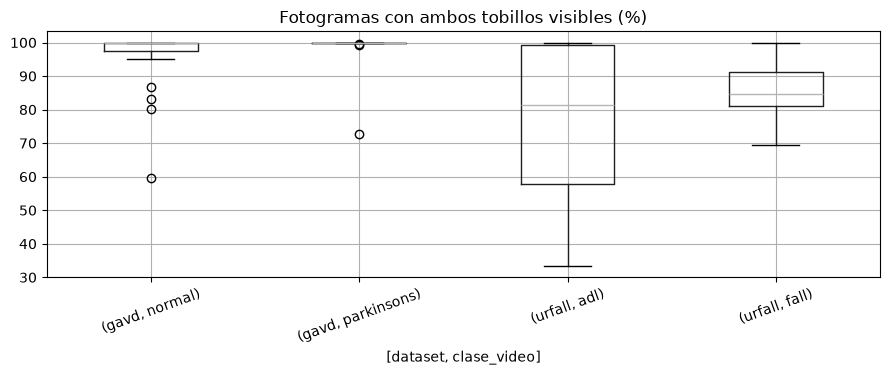

In [8]:
resumen = (pose_index.groupby(['dataset', 'clase_video'])
           [['pct_persona', 'pct_tobillos', 'pct_caderas', 'conf_media', 'duracion_s']].mean().round(2))
display(resumen)

# Clips problemáticos: menos del 80 % de fotogramas con tobillos visibles
malos = pose_index[pose_index['pct_tobillos'] < 80][['clip_id', 'pct_persona', 'pct_tobillos', 'duracion_s']]
print(f"\nClips con tobillos visibles < 80 %: {len(malos)} de {len(pose_index)}")
display(malos)

fig, ax = plt.subplots(figsize=(9, 4))
pose_index.boxplot(column='pct_tobillos', by=['dataset', 'clase_video'], ax=ax, rot=20)
ax.set_title('Fotogramas con ambos tobillos visibles (%)'); plt.suptitle('')
plt.tight_layout(); plt.show()

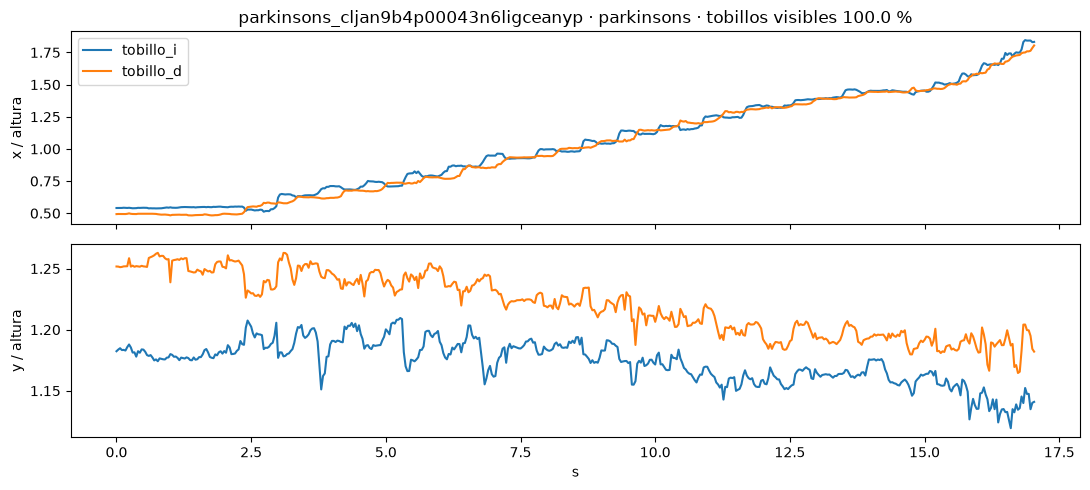

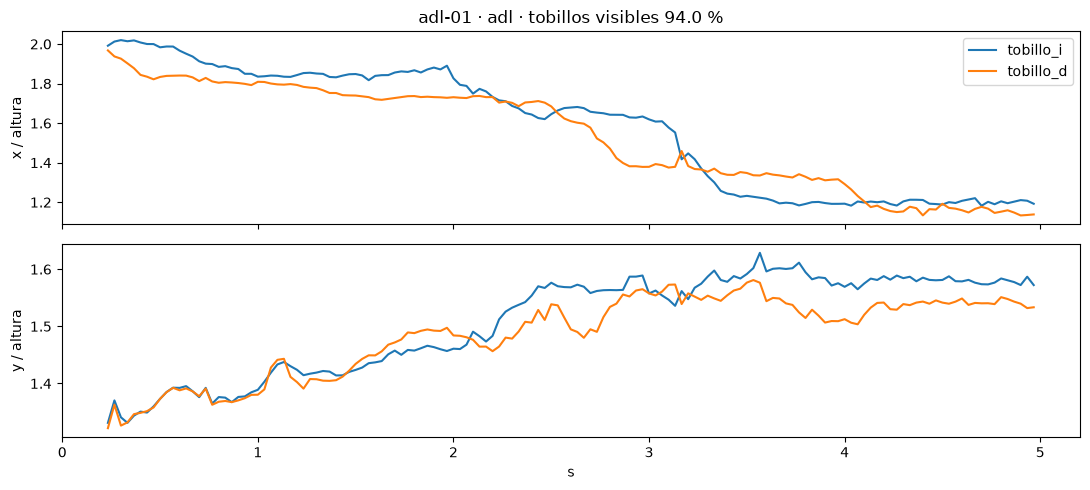

In [9]:
def graficar_tobillos(clip_id: str):
    fila = pose_index[pose_index['clip_id'] == clip_id].iloc[0]
    d = np.load(fila['pose_path'])
    t = np.arange(len(d['kpts_xy'])) / float(d['fps'])
    # Coordenada x normalizada por la altura de la caja (aproximación a la normalización por escala)
    alto = np.nanmedian(d['bbox'][:, 3] - d['bbox'][:, 1])
    fig, axes = plt.subplots(2, 1, figsize=(11, 5), sharex=True)
    for nombre in ['tobillo_i', 'tobillo_d']:
        axes[0].plot(t, d['kpts_xy'][:, KPT[nombre], 0] / alto, label=nombre)
        axes[1].plot(t, d['kpts_xy'][:, KPT[nombre], 1] / alto, label=nombre)
    axes[0].set_ylabel('x / altura'); axes[1].set_ylabel('y / altura'); axes[1].set_xlabel('s')
    axes[0].set_title(f"{clip_id} · {fila['clase_video']} · tobillos visibles {fila['pct_tobillos']} %")
    axes[0].legend(); plt.tight_layout(); plt.show()

graficar_tobillos(pose_index[pose_index['clase_video'] == 'parkinsons']['clip_id'].iloc[0])
graficar_tobillos(pose_index[pose_index['dataset'] == 'urfall']['clip_id'].iloc[0])

## 5. Decisión pendiente: ¿de dónde salen las etiquetas de *bloqueo*?

Hasta ahora **solo tenemos etiquetas de vídeo** (`parkinsons` / `normal`; `adl` / `fall`). Ninguna indica *cuándo* ocurre un episodio de bloqueo, que es justo lo que pide el Trabajo 15 (localizar en el tiempo). Esta celda explora qué trae GAVD en la columna `gait_event` para valorar si sirve como ancla de etiquetado.

In [10]:
ann_dir = BASE_DIR / 'raw' / 'gavd' / 'annotations'
df_ann = pd.concat([pd.read_csv(f, low_memory=False) for f in sorted(ann_dir.glob('*.csv'))], ignore_index=True)
print('Columnas:', list(df_ann.columns))
print('\nValores de gait_event (todo el dataset):')
print(df_ann['gait_event'].astype(str).value_counts(dropna=False).head(15))
print('\nValores de gait_event en parkinsons:')
print(df_ann.loc[df_ann['gait_pat'].str.lower() == 'parkinsons', 'gait_event'].astype(str).value_counts(dropna=False).head(15))
print('\nVistas de cámara (cam_view) en parkinsons:')
print(df_ann.loc[df_ann['gait_pat'].str.lower() == 'parkinsons', 'cam_view'].value_counts())

Columnas: ['seq', 'frame_num', 'cam_view', 'gait_event', 'dataset', 'gait_pat', 'bbox', 'vid_info', 'id', 'url']

Valores de gait_event (todo el dataset):
gait_event
NaN                      457358
Right initial contact       383
Left initial contact        368
Left tibia vertical           3
Left toe off                  2
Left foot flat                2
Name: count, dtype: int64

Valores de gait_event en parkinsons:
gait_event
NaN                      10370
Right initial contact       29
Left initial contact        27
Name: count, dtype: int64

Vistas de cámara (cam_view) en parkinsons:
cam_view
front         3849
right side    2453
back          2378
left side     1746
Name: count, dtype: int64


### Qué hacer con el resultado (para hablarlo con el compañero)

| Opción | Idea | Pros | Contras |
|---|---|---|---|
| **A. Dataset con bloqueos etiquetados** | Ribeiro De Souza et al. (2022, *Front. Neurosci.*): 35 pacientes con FoG, vídeo + IMU, tarea de giro en el sitio, episodios anotados. Comprobar enlace de descarga y licencia en el artículo. | Etiquetas reales de FoG; incluye giros (lo pide el enunciado) | Hay que verificar acceso, tamaño y formato |
| **B. Etiquetas sintéticas** | Tomar marcha normal (GAVD normal) e insertar tramos "bloqueo" simulados sobre el esqueleto: *akinético* (piernas quietas) y *temblor* (oscilación 3–8 Hz de tobillos/rodillas). Las paradas de UR Fall = parada voluntaria. | Control total, mucho dato, se puede variar perspectiva y oclusión | Es simulación: hay que decirlo claramente en el póster |
| **C. Pseudoetiquetas por reglas** | Marcar como "bloqueo" los tramos de GAVD-parkinsons con velocidad de tobillos baja + Freeze Index alto | Sin anotar a mano | Circular: el modelo aprende la regla |

**Propuesta:** A para validar (si es accesible) + B para entrenar y probar robustez + un detector de reglas (Freeze Index + velocidad) como **método base** de comparación, que además exige el enunciado.

## Dudas

Decisión para mañana: etiquetas de bloqueo

Es lo más importante que tenéis que decidir juntos. Mi propuesta, que habría que confirmar con el profesor:

- Validar con datos reales: hay un dataset público con bloqueos anotados en vídeo (Ribeiro De Souza et al., 2022, Frontiers in Neuroscience): 35 pacientes con FoG en una tarea de giro en el sitio, con vídeo, sensores inerciales y episodios. No he comprobado el enlace de descarga ni la licencia; está en el artículo (DOI 10.3389/fnins.2022.832463).
- Entrenar con bloqueos simulados: insertar tramos de "bloqueo" sobre esqueletos de marcha normal, de dos tipos: piernas inmóviles y temblor de 3 a 8 Hz. Las paradas de UR Fall harían de parada voluntaria. En el póster hay que decir claramente que es simulación.
- Método base por reglas: el enunciado pide comparar con uno, y el detector por Freeze Index y velocidad cumple ese papel.

Si el dataset de Ribeiro De Souza resulta accesible, cambia bastante el trabajo, porque pasaríais a tener etiquetas reales. Es lo primero que yo comprobaría mañana.

## Análisis de los resultados

Qué está bien:

- GAVD: persona detectada en el 100 % de los fotogramas y tobillos visibles en el 95 % (normal) y el 98,7 % (Parkinson), con confianza media de 0,83-0,85. Es una pose muy utilizable.
- Gráfica de Parkinson: se ven los pasos como escalones en x y oscilaciones en y. Entre 0 y 2,4 s la persona está quieta y luego arranca, es decir, hay una parada real en los datos. Un detector de pasos funcionaría bien sobre esto.
- No hay saltos raros entre personas ni trayectorias imposibles, así que la selección por solape funciona.
- Balance de clases del índice: 76 clips, 19 normal, 22 Parkinson, 25 ADL y 10 caídas, que cuadra con lo descargado.

Tres cosas que cambian el plan:

1. GAVD no trae etiquetas de bloqueo. La sección 5 lo confirma: gait_event está vacío en el 99,8 % de las filas. En Parkinson solo hay 56 marcas (todas "initial contact", el apoyo del talón). Esto cierra la opción de usar GAVD como fuente de bloqueos, y deja como alternativas el dataset de Ribeiro De Souza (2022) y los bloqueos simulados. Esas 56 marcas solo sirven, como mucho, para validar un detector de pasos.

2. Sí tenéis la vista de cámara, y es oro para el enunciado. cam_view distingue frontal, trasera y lateral derecha/izquierda (por fotogramas: 3849 frontal, 2453 lateral derecha, 2378 trasera, 1746 lateral izquierda). Con eso podéis medir cómo cae el rendimiento al cambiar de perspectiva, que es justo lo que pide el Trabajo 15. Pero metadata_gavd.csv no la guarda: habría que añadir cam_view a cada clip desde las anotaciones. Asumo que cada secuencia tiene una única vista; conviene comprobarlo.

3. Los clips son cortos y hay poco material. En total son unos 9 minutos de vídeo con pose: 110 s de GAVD normal, 220 s de Parkinson, 179 s de ADL y 46 s de caídas. Algunos clips de GAVD duran 1,5-2 s, y con ventanas de 2-3 s no dan ni una ventana. Habría que descartar los clips de menos de unos 3 s para el modelo. Esto refuerza la idea de apoyarse en simulación o en el dataset externo.